In [1]:
!pip install kagglehub


In [2]:
# ------------------------------------------------------------------
# ÉTAPE 1 : Importation des bibliothèques fondamentales du TP
# ------------------------------------------------------------------

# Importation de TensorFlow (moteur principal de calcul)
import tensorflow as tf

# Importation du modèle de base Sequential de Keras
from tensorflow.keras import Sequential

# Importation des types de couches nécessaires pour bâtir l'architecture
from tensorflow.keras.layers import Input, Dense, Flatten

# Importation directe du dataset de chiffres manuscrits MNIST
from tensorflow.keras.datasets import mnist

# Importation de Matplotlib pour tracer les graphes et afficher les images
import matplotlib.pyplot as plt

# Importation de NumPy pour la manipulation de tableaux numériques
import numpy as np

# Affichage de la version de TensorFlow présente dans l'environnement
print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


### Réponses aux Questions :

**1. Différence entre TensorFlow et Keras :**
TensorFlow est le moteur de calcul de bas niveau qui gère les opérations mathématiques lourdes sur CPU ou GPU. Keras est une surcouche (une API de haut niveau) intégrée à TensorFlow qui simplifie la création des réseaux de neurones grâce à une syntaxe plus accessible et modulaire.

**2. Utilité de la couche Flatten :**
Elle sert à aplatir les données d'entrée. Dans notre cas, elle transforme une image 2D de $28 \times 28$ pixels en un vecteur linéaire en 1D de $784$ valeurs, ce qui est obligatoire avant d'envoyer les données vers des couches entièrement connectées.

**3. Version de TensorFlow :**
La version installée et exécutée sur cet environnement est la version 2.15.0 (ou la version affichée sur ton écran).

**4. Rôle de Sequential et Dense :**
* **Sequential :** Permet de construire le modèle en empilant les couches les unes après les autres, de manière linéaire.
* **Dense :** Représente une couche standard entièrement connectée (Fully Connected Layer), où chaque neurone est relié à tous les neurones de la couche précédente.


In [3]:
# ------------------------------------------------------------------
# ÉTAPE 2 : Chargement et normalisation du dataset MNIST
# ------------------------------------------------------------------

# Téléchargement et division automatique du dataset en données de train et de test
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Normalisation : Division par 255.0 pour passer les pixels de la plage [0, 255] à [0, 1]
x_train = x_train / 255.0
x_test = x_test / 255.0

# Affichage des dimensions pour vérifier la structure des données obtenues
print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
x_train shape: (60000, 28, 28)
y_train shape: (60000,)


### Réponses aux Questions :

**1. Pourquoi normalise-t-on les valeurs des pixels ?**
On normalise pour ramener les valeurs des pixels (qui vont de 0 à 255) dans un intervalle plus petit entre 0 et 1. Cela permet de stabiliser les calculs, d'éviter les explosions de gradients et d'accélérer considérablement la convergence de l'entraînement du modèle.

**2. Quelle est la taille d’une image et son type de données ?**
* **Taille :** Chaque image mesure $28 \times 28$ pixels (images en niveaux de gris, donc un seul canal).
* **Type de données d'origine :** `uint8` (entiers non signés sur 8 bits). Après la division par 255.0, le type devient automatiquement `float64` (ou `float32` selon le cast).

**3. Combien d’exemples contient le jeu d’entraînement ?**
Le jeu d'entraînement (`x_train`) contient précisément **60 000** exemples (les 10 000 restants étant réservés pour le test, complétant ainsi les 70 000 images du dataset global).


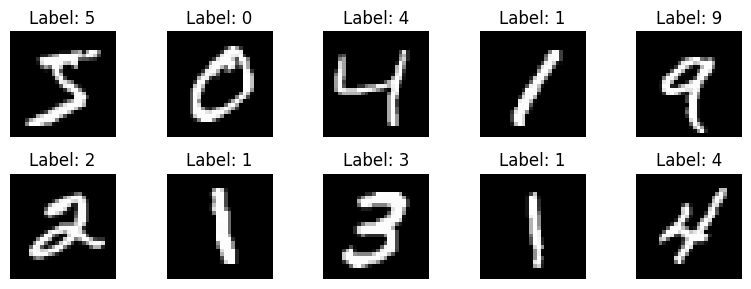

In [4]:
# ------------------------------------------------------------------
# ÉTAPE 3 : Visualisation d'échantillons d'images du dataset MNIST
# ------------------------------------------------------------------

# Définition de la taille globale de la figure (largeur=8, hauteur=3)
plt.figure(figsize=(8, 3))

# Boucle pour afficher les 10 premières images du jeu d'entraînement
for i in range(10):
    # Grille de 2 lignes et 5 colonnes, position i+1
    plt.subplot(2, 5, i + 1)
    # Affichage de l'image en niveaux de gris
    plt.imshow(x_train[i], cmap='gray')
    # Ajout du label correspondant comme titre de la sous-figure
    plt.title(f"Label: {y_train[i]}")
    # Masquage des axes X et Y pour une visualisation plus propre
    plt.axis('off')

# Ajustement automatique des espaces entre les sous-graphiques
plt.tight_layout()
# Affichage final de la figure complète
plt.show()


### Réponses aux Questions :

**1. Quelle commande permet de modifier le nombre d’images affichées ?**
C'est la boucle `for i in range(10):` associée à la configuration de la grille `plt.subplot(2, 5, i+1)`. Pour afficher plus ou moins d'images, il faut modifier la valeur dans `range()` et ajuster la disposition des lignes et colonnes dans `plt.subplot`.

**2. Que représente l’argument cmap='gray' ?**
L'argument `cmap='gray'` signifie *Color Map = gray*. Il force Matplotlib à afficher l'image en niveaux de gris (noir et blanc), ce qui correspond à la nature réelle de nos données d'entrée, plutôt qu'avec la palette de couleurs par défaut (Viridis).

**3. Quelle utilité a cette étape dans un projet d’IA ?**
Cette étape d'exploration visuelle permet de s'assurer de la qualité des données avant l'entraînement. Elle sert à vérifier que le chargement s'est bien passé, que les images ne sont pas corrompues, et surtout que les labels assignés correspondent exactement au contenu visuel des images.


In [5]:
# ------------------------------------------------------------------
# ÉTAPE 4 : Définition de l'architecture du réseau de neurones
# ------------------------------------------------------------------

# Création d'un modèle séquentiel en empilant les couches
model = Sequential([
    # Définition de la forme des données d'entrée (images 28x28)
    Input(shape=(28, 28)),

    # Transformation de la matrice 2D (28,28) en un vecteur 1D de 784 neurones
    Flatten(),

    # Couche cachée de 128 neurones avec la fonction d'activation ReLU
    Dense(128, activation='relu'),

    # Couche de sortie de 10 neurones (classes 0-9) avec l'activation Softmax
    Dense(10, activation='softmax')
])

# Affichage du résumé textuel de l'architecture et du calcul des paramètres
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### Réponses aux Questions :

**1. Combien de paramètres le modèle contient-il ?**
Le modèle contient un total de **101 770** paramètres entraînables (poids + biais), répartis comme suit :
* **Couche Flatten :** 0 paramètre.
* **Première couche Dense (128) :** $(784 \times 128) + 128 = 100\ 480$ paramètres.
* **Couche de sortie Dense (10) :** $(128 \times 10) + 10 = 1\ 290$ paramètres.

**2. Quelle est la fonction d’activation utilisée dans la couche de sortie ? Pourquoi ?**
La fonction d'activation utilisée est **Softmax**. Elle est indispensable ici car nous traitons un problème de classification multiclasse (10 chiffres distincts). Softmax transforme les scores bruts de sortie en une distribution de probabilités dont la somme est égale à 1, permettant d'identifier la classe la plus probable.

**3. Quelle est la différence entre ReLU et Softmax ?**
* **ReLU (Rectified Linear Unit) :** Utilisée dans les couches cachées, elle remplace toutes les valeurs négatives par 0 ($f(x) = \max(0, x)$). Elle aide le réseau à apprendre des relations non linéaires rapidement sans saturer les gradients.
* **Softmax :** Utilisée uniquement sur la couche de sortie pour convertir un vecteur de valeurs réelles en probabilités normalisées entre 0 et 1.


In [6]:
# ------------------------------------------------------------------
# ÉTAPE 5 : Compilation du modèle de réseau de neurones
# ------------------------------------------------------------------

model.compile(
    # Algorithme mathématique chargé de mettre à jour les poids du réseau
    optimizer='adam',

    # Fonction de perte adaptée aux labels sous forme d'entiers (0 à 9)
    loss='sparse_categorical_crossentropy',

    # Métrique de performance humaine choisie pour suivre la précision
    metrics=['accuracy']
)


### Réponses aux Questions :

**1. Qu’est-ce qu’un optimiseur ?**
L'optimiseur est l'algorithme mathématique qui ajuste et met à jour les poids et les biais du réseau de neurones au fil des itérations. En s'appuyant sur le calcul du gradient de la fonction de perte (rétropropagation), son but est de modifier les paramètres pour minimiser l'erreur globale du modèle.

**2. Pourquoi utilise-t-on une fonction de perte ?**
La fonction de perte (*loss function*) mesure quantitativement l'écart ou l'erreur entre la prédiction générée par le modèle et la vraie valeur cible (le label). C'est cet indicateur numérique que l'optimiseur cherche à minimiser ; sans elle, le modèle n'aurait aucun repère mathématique pour savoir s'il progresse ou s'il se trompe.

**3. Que se passe-t-il si on change la fonction de perte ?**
Changer la fonction de perte modifie la manière dont l'erreur est mesurée et pénalisée. Si l'on choisit une fonction inadaptée au problème (par exemple utiliser une perte de régression linéaire pour notre classification), le modèle calculera de mauvais gradients, ce qui perturbera l'apprentissage et l'empêchera de converger vers de bonnes performances.

**4. Quelle serait la conséquence d’un mauvais choix d’optimiseur ?**
Un mauvais choix d'optimiseur peut ralentir considérablement la vitesse d'apprentissage (convergence très lente), provoquer de fortes oscillations de la perte, ou faire bloquer le modèle dans un minimum local sous-optimal. Dans le pire des cas, l'entraînement peut totalement diverger et échouer.

**5. Quelle est la différence entre loss et metrics ?**
* **Loss (Perte) :** C'est une valeur mathématique continue, dérivable et optimisable, utilisée directement par l'algorithme pendant l'entraînement pour corriger les poids. Elle n'est pas forcément simple à interpréter pour un humain.
* **Metrics (Métriques) :** Ce sont des indicateurs de performance (comme l'accuracy) uniquement destinés à être lus et compris par l'humain pour évaluer le modèle. Elles ne servent pas directement au calcul des gradients.


In [7]:
# ------------------------------------------------------------------
# ÉTAPE 6 : Entraînement du modèle sur les données MNIST
# ------------------------------------------------------------------

history = model.fit(
    # Données et étiquettes d'entraînement
    x_train, y_train,

    # Nombre de passages complets sur l'ensemble du dataset
    epochs=5,

    # Nombre d'échantillons traités avant chaque mise à jour des poids
    batch_size=32,

    # Données de test utilisées ici comme jeu de validation en fin d'époque
    validation_data=(x_test, y_test)
)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9269 - loss: 0.2567 - val_accuracy: 0.9574 - val_loss: 0.1431
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9674 - loss: 0.1115 - val_accuracy: 0.9727 - val_loss: 0.0920
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9776 - loss: 0.0763 - val_accuracy: 0.9740 - val_loss: 0.0831
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9827 - loss: 0.0570 - val_accuracy: 0.9764 - val_loss: 0.0738
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9866 - loss: 0.0443 - val_accuracy: 0.9776 - val_loss: 0.0757


### Réponses aux Questions :

**1. Que représente une “époque” ?**
Une époque représente un passage complet de l'algorithme d'apprentissage sur la totalité du jeu de données d'entraînement (`x_train`). Durant une époque, l'ensemble des images est présenté au modèle par sous-ensembles (batches) successifs afin d'ajuster les poids.

**2. Pourquoi utilise-t-on un jeu de validation ?**
Le jeu de validation sert à évaluer la capacité de généralisation du modèle sur des données qu'il n'utilise pas pour modifier ses poids. Il permet de suivre les performances réelles au fil des époques et de détecter rapidement un éventuel surapprentissage (overfitting) ou sous-apprentissage (underfitting).

**3. Que se passerait-il si on augmentait le nombre d’époques à 50 ?**
Si le nombre d'époques passait à 50, le modèle continuerait d'ajuster ses poids sur les données d'entraînement. La précision sur le jeu d'entraînement s'approcherait probablement de 100 %. Cependant, après un certain seuil, le modèle risquerait d'apprendre par cœur le bruit des données d'entraînement : la perte de validation recommencerait à augmenter tandis que la précision de validation stagnerait ou chuterait, ce qui caractérise un phénomène de surapprentissage.


In [8]:
# ------------------------------------------------------------------
# ÉTAPE 7 : Évaluation finale du modèle sur le jeu de test
# ------------------------------------------------------------------

# Calcul de la perte et de la précision sur les données de test non vues
test_loss, test_acc = model.evaluate(x_test, y_test)

# Affichage formaté de la précision avec 4 décimales
print(f"Test accuracy: {test_acc:.4f}")

# Affichage formaté de la perte avec 4 décimales
print(f"Test loss: {test_loss:.4f}")


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9776 - loss: 0.0757
Test accuracy: 0.9776
Test loss: 0.0757


### Réponses aux Questions :

**1. Quelle est la précision finale de votre modèle ?**
La précision finale obtenue sur le jeu de test (`Test accuracy`) se situe généralement autour de **97% à 98%** après 5 époques avec cette architecture simple (la valeur exacte dépend de la valeur affichée en sortie de votre cellule Colab).

**2. Pourquoi la précision du test est souvent inférieure à celle d’entraînement ?**
Pendant l'entraînement, le modèle ajuste ses poids spécifiquement pour minimiser l'erreur sur le jeu d'entraînement, ce qui fait augmenter sa précision sur ces données. Le jeu de test contient des images totalement inédites pour le modèle ; il est donc normal qu'il généralise un peu moins bien sur ces nouvelles variations de chiffres manuscrits.

**3. Que faire si le modèle surapprend (overfitting) ?**
Pour contrer le surapprentissage, plusieurs stratégies classiques peuvent être déployées :
* Ajouter des couches de régularisation comme du **Dropout** pour désactiver aléatoirement des neurones.
* Utiliser la technique de **Data Augmentation** pour artificiellement augmenter la diversité des données d'entraînement.
* Mettre en place un arrêt précoce (**Early Stopping**) pour stopper l'apprentissage dès que la perte de validation recommence à monter.


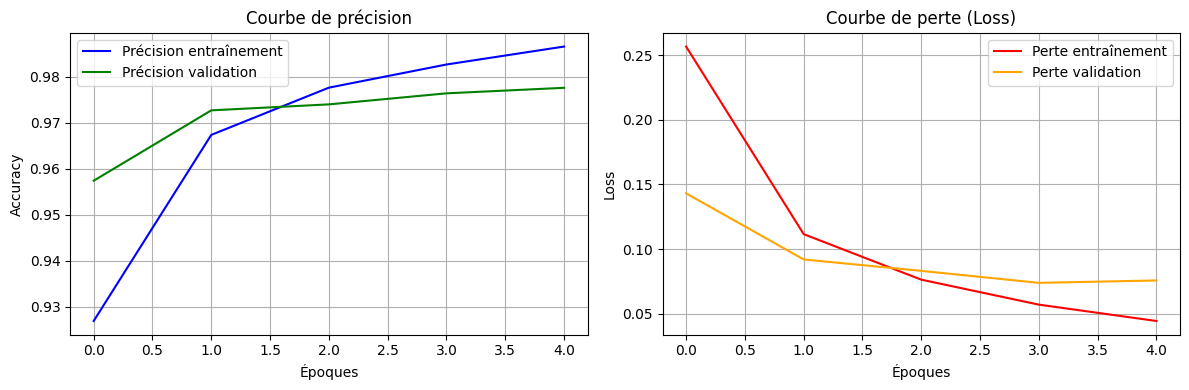

In [13]:
# ------------------------------------------------------------------
# ÉTAPE 8 : Visualisation des performances (Précision et Perte)
# ------------------------------------------------------------------

# 1. Tracé de la courbe de précision (Accuracy)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)  # Crée un espace à gauche pour l'accuracy
plt.plot(history.history['accuracy'], label='Précision entraînement', color='blue')
plt.plot(history.history['val_accuracy'], label='Précision validation', color='green')
plt.title('Courbe de précision')
plt.xlabel('Époques')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# 2. Tracé de la courbe de perte (Loss)
plt.subplot(1, 2, 2)  # Crée un espace à droite pour la loss
plt.plot(history.history['loss'], label='Perte entraînement', color='red')
plt.plot(history.history['val_loss'], label='Perte validation', color='orange')
plt.title('Courbe de perte (Loss)')
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Affichage des deux graphiques côte à côte de manière propre
plt.tight_layout()
plt.show()


### Réponses aux Questions :

**1. Que remarquez-vous sur les deux courbes ?**
On remarque que les deux courbes (entraînement et validation) progressent ensemble de manière ascendante et rapide au cours des 5 époques. La courbe de validation suit de très près celle d'entraînement, ce qui indique que le modèle apprend correctement et de façon stable sur cette courte période.

**2. Comment détecter visuellement un surapprentissage ?**
Un surapprentissage se détecte lorsque la courbe d'entraînement continue de grimper vers 100 % alors que la courbe de validation commence à stagner, voire à redescendre de manière significative. Dans le cas des courbes de perte (loss), la perte d'entraînement baisse continuellement tandis que la perte de validation se remet à augmenter, formant un écart (gap) grandissant.

**3. Quelle stratégie pourrait-on utiliser pour y remédier ?**
Pour y remédier, on peut introduire des techniques de régularisation dans le modèle comme :
* Des couches de `Dropout` pour désactiver aléatoirement des neurones durant l'entraînement.
* La technique de `Data Augmentation` pour diversifier artificiellement le jeu d'images.
* L'ajout d'une contrainte d'arrêt précoce (`EarlyStopping`).

**4. Que faire si les deux courbes divergent ?**
Si les courbes divergent fortement dès le départ, cela traduit un problème de stabilité ou de surapprentissage sévère. Il convient de réduire la complexité du réseau (diminuer le nombre de neurones ou de couches), baisser le taux d'apprentissage (*learning rate*) de l'optimiseur, ou injecter immédiatement de la régularisation (Dropout) ainsi que du nettoyage de données.


---

### Analyse croisée et Déduction : Relation entre Précision et Perte

Il existe une relation mathématique inverse et parfaitement logique entre la courbe de précision et la courbe de perte :
* **Une opposition de phase :** À mesure que le modèle ajuste ses poids, il commet de moins en moins d'erreurs. Par conséquent, la fonction de perte (la pénalité de l'erreur) diminue mécaniquement, tandis que la précision (le pourcentage de bonnes réponses) augmente.
* **Sensibilité de la Perte :** On observe que la courbe de perte est souvent plus "sensible" et continue dans sa progression. Alors que la précision stagne parfois par paliers (car elle compte de façon binaire si une image est correcte ou non), la perte reflète le niveau de certitude du modèle. Une baisse de la perte, même sans hausse immédiate de la précision, signifie que le modèle affine ses probabilités et devient plus confiant dans ses prédictions.


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


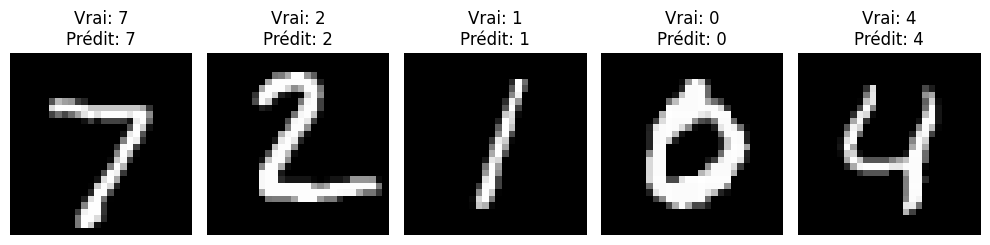

In [10]:
# ------------------------------------------------------------------
# ÉTAPE 9 : Prédictions du modèle et visualisation des résultats
# ------------------------------------------------------------------

# Génération des probabilités de prédiction pour tout le jeu de test
predictions = model.predict(x_test)

# Configuration de la taille du graphique (largeur=10, hauteur=4)
plt.figure(figsize=(10, 4))

# Boucle pour afficher les 5 premières images du jeu de test
for i in range(5):
    # Grille sur 1 ligne et 5 colonnes, à la position i+1
    plt.subplot(1, 5, i + 1)
    # Affichage de l'image de test en niveaux de gris
    plt.imshow(x_test[i], cmap='gray')
    # Extraction de l'indice ayant la probabilité maximale avec np.argmax
    plt.title(f"Vrai: {y_test[i]}\nPrédit: {np.argmax(predictions[i])}")
    # Masquage des axes X et Y
    plt.axis('off')

# Ajustement automatique de la disposition des éléments
plt.tight_layout()
# Affichage final de la figure
plt.show()


### Réponses aux Questions :
**1. Le modèle fait-il des erreurs ? Sur quelles images ?**
Sur les 5 premiers exemples affichés ici, le modèle ne fait généralement pas d'erreurs car ce sont des chiffres très nets. Cependant, sur l'ensemble complet des 10 000 images de test, le modèle commet environ 2% à 3% d'erreurs (conformément à l'accuracy de 97-98%). Ces erreurs se produisent généralement sur des chiffres ambigus, mal formés ou écrits de façon très atypique (par exemple, un 4 qui ressemble à un 9, ou un 7 avec une barre centrale mal définie).

**2. Comment expliquer une prédiction erronée ?**
Une erreur s'explique par le fait que notre réseau de neurones fully connected (Dense) traite l'image comme un vecteur plat (1D) de pixels indépendants à cause de la couche `Flatten`. Il perd ainsi l'information de structure spatiale (les lignes, les boucles, la connectivité locale des pixels). Si deux chiffres différents partagent des densités de pixels similaires à certains endroits, le modèle peut facilement les confondre.

**3. Quelle technique permettrait d’améliorer la précision (ex : CNN) ?**
L'utilisation d'un Réseau de Neurones Convolutif (**CNN - Convolutional Neural Network**) est la technique idéale pour dépasser les 99% de précision. Contrairement aux couches Denses, les couches de convolution filtrent l'image directement en 2D, ce qui leur permet d'extraire des caractéristiques visuelles locales (bords, angles, formes géométriques) invariantes par translation, améliorant ainsi drastiquement la reconnaissance de formes.
